In [12]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Data preparation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Machine learning models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    RocCurveDisplay
)

# Settings
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [13]:
from google.colab import files

uploaded = files.upload()

Saving bank-additional-full.csv to bank-additional-full (1).csv


In [14]:
from pathlib import Path

data_path = Path("bank-additional-full.csv")

if not data_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {data_path.resolve()}"
    )

df = pd.read_csv(data_path, sep=";")

df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Confirm that the dataset has loaded correctly

In [15]:
# Display the first five records
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Now I will check the dataset dimention before any analysis

In [16]:
# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 41188
Number of columns: 21


Understand the variables and data types

In [17]:

# Display column names and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [18]:

# Statistical summary of numerical variables
df.describe()


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [19]:

# Statistical summary of categorical variables
df.describe(include='object')


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


Examine the target variable
This is one of the most important steps because we need to understand whether the dataset is balanced.

In [20]:

# Frequency of subscription outcomes
print(df['y'].value_counts())

# Percentage distribution
print(df['y'].value_counts(normalize=True) * 100)


y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


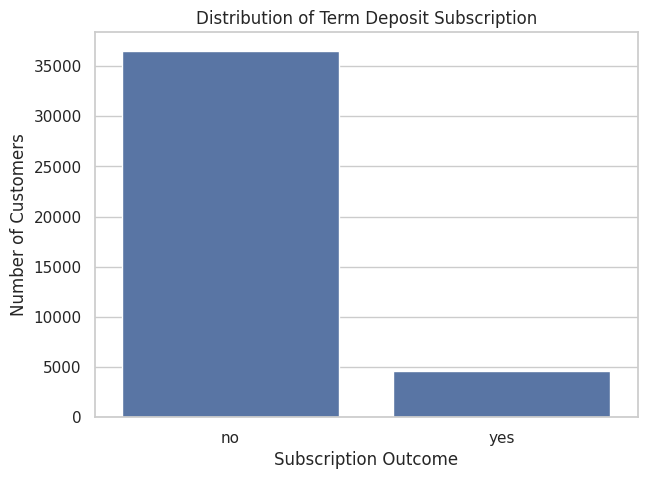

In [21]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title('Distribution of Term Deposit Subscription')
plt.xlabel('Subscription Outcome')
plt.ylabel('Number of Customers')

plt.show()


Check missing values

In [22]:

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])


Series([], dtype: int64)


All columns have complete data. Therefore, no missing-value imputation or deletion is required at this stage.

Now lets Check for duplicated records

In [23]:

print("Duplicate records:", df.duplicated().sum())


Duplicate records: 12


There are duplicates which may cause certain customer observations to be counted more than once, potentially affecting model performance.

In [24]:
df = df.drop_duplicates()

In [25]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [26]:
print(df.shape)

(41176, 21)


Twelve duplicate records were identified and removed to prevent repeated observations from potentially distorting the model's learning process.

Checking for  unique values in categorical variables

In [27]:

categorical_columns = df.select_dtypes(
    include='object'
).columns

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts().head(10))



 job
job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
Name: count, dtype: int64

 marital
marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64

 education
education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64

 default
default
no         32577
unknown     8596
yes            3
Name: count, dtype: int64

 housing
housing
yes        21571
no         18615
unknown      990
Name: count, dtype: int64

 loan
loan
no         33938
yes         6248
unknown      990
Name: count, dtype: int64

 contact
contact
cellular     26135
telephone    15041
Nam

**Explore relationships between variables and subscription**

We want to understand which customer characteristics are associated with subscribing.

**`Subscription by age`**

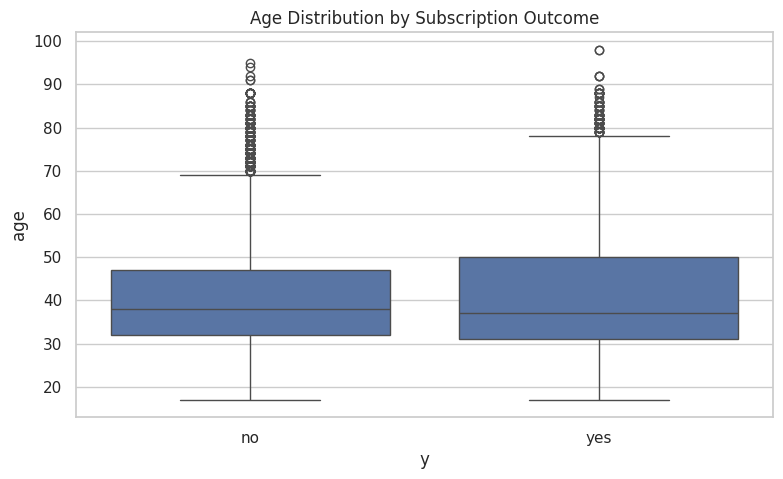

In [28]:

plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='y', y='age')

plt.title('Age Distribution by Subscription Outcome')
plt.show()


The categorical variables contain several distinct customer characteristics, including occupation, marital status, education, credit status and previous campaign outcomes. The analysis also reveals the presence of unknown categories, particularly in the default variable. These will be retained as distinct categories during initial modelling rather than treated as conventional missing values.

**Subscription by job category**

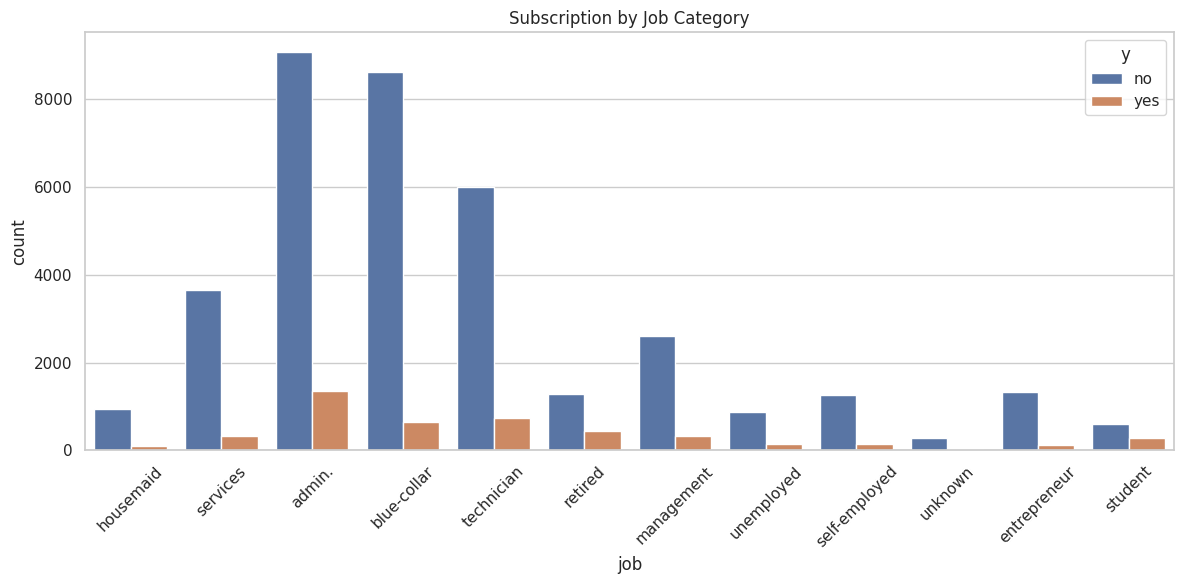

In [29]:

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='job',
    hue='y'
)

plt.xticks(rotation=45)
plt.title('Subscription by Job Category')
plt.tight_layout()
plt.show()


Although admin customers contribute the highest number of subscriptions, this does not necessarily mean they have the highest subscription rate. The chart displays counts, not percentages.

Now we shall Calculate the subscription rate for each job category to make a fair comparison.

In [30]:
job_subscription = pd.crosstab(
    df['job'], df['y'], normalize='index'
) * 100

print(job_subscription.sort_values('yes', ascending=False))

y                     no        yes
job                                
student        68.571429  31.428571
retired        74.738068  25.261932
unemployed     85.798817  14.201183
admin.         87.033305  12.966695
management     88.782490  11.217510
unknown        88.787879  11.212121
technician     89.167532  10.832468
self-employed  89.514426  10.485574
housemaid      90.000000  10.000000
entrepreneur   91.483516   8.516484
services       91.857827   8.142173
blue-collar    93.104939   6.895061


Job category appears to be an informative predictor of term-deposit subscription. Students and retired customers demonstrate substantially higher subscription rates than blue-collar and services workers.

Importantly, these are associations and do not establish that occupation causes subscription.

**Subscription by education**

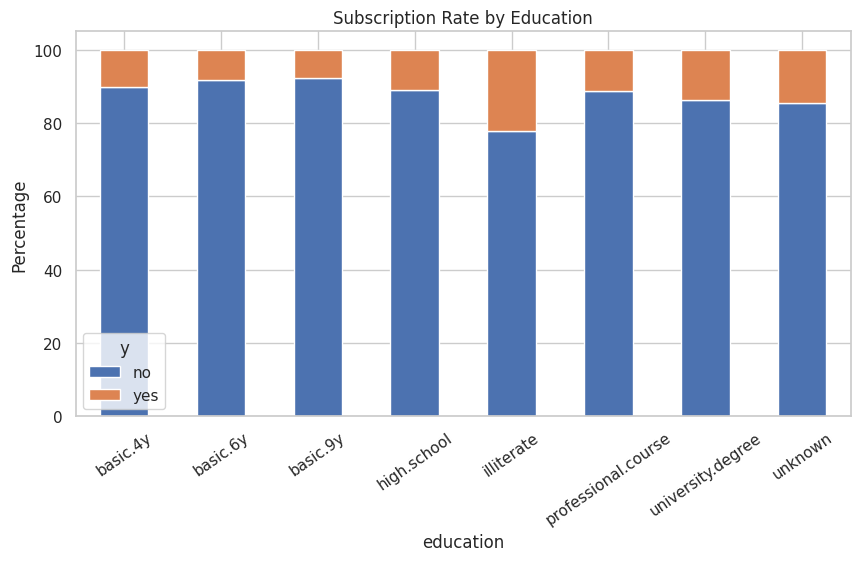

In [31]:

education_rate = pd.crosstab(
    df['education'],
    df['y'],
    normalize='index'
) * 100

education_rate.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.title('Subscription Rate by Education')
plt.ylabel('Percentage')
plt.xticks(rotation=35)
plt.show()


Education level appears to be associated with term-deposit subscription. Interestingly, customers classified as illiterate show a relatively high subscription rate.

However, the illiterate category has only 18 observations, so this percentage should be interpreted cautiously

In [32]:
education_rate = pd.crosstab(
    df['education'], df['y'], normalize='index'
) * 100

print(education_rate.sort_values('yes', ascending=False))

y                           no        yes
education                                
illiterate           77.777778  22.222222
unknown              85.491329  14.508671
university.degree    86.279184  13.720816
professional.course  88.645038  11.354962
high.school          89.161060  10.838940
basic.4y             89.750958  10.249042
basic.6y             91.793976   8.206024
basic.9y             92.175352   7.824648


Customers with university degrees and professional qualifications generally show higher subscription rates than those with basic education.

However, the relationship is not strictly linear. Education level appears to provide useful information for predicting subscription, although it should be combined with other variables.

In [33]:
marital_rate = pd.crosstab(
    df['marital'], df['y'], normalize='index'
) * 100

print(marital_rate.sort_values('yes', ascending=False))

y                no        yes
marital                       
unknown   85.000000  15.000000
single    85.991007  14.008993
divorced  89.676860  10.323140
married   89.843907  10.156093


Single customers demonstrate a higher subscription rate than married and divorced customers. Marital status may therefore provide useful information when predicting term-deposit subscription

**Data preparation**

Two variables require special consideration during data preparation: duration and pdays.

The variable duration represents the length of a telephone conversation in seconds. Although call duration may be strongly associated with subscription outcomes, it is only known after a customer has been contacted. Since the objective is to identify potential subscribers before initiating a marketing call, including this variable would introduce data leakage. Consequently, duration will be excluded from the predictive model while remaining available for exploratory analysis.

The variable pdays represents the number of days since a customer was last contacted during a previous campaign. A value of 999 indicates that the customer was not previously contacted. Rather than interpreting 999 as an actual number of days, an additional binary indicator, previously_contacted, will be created to distinguish previously contacted customers from those without prior campaign contact. This preserves the information while avoiding misleading numerical interpretation

We will remove duration from the predictors because it introduces data leakage.

In [34]:
df = df.drop(columns=['duration'])

Create a new variable called previously_contacted.

In [35]:
df['previously_contacted'] = (df['pdays'] != 999).astype(int)

Replace 999 with NaN so that it is not treated as an actual number of days.

In [36]:
df['pdays'] = df['pdays'].replace(999, np.nan)

In [37]:
print("Duration column exists:", 'duration' in df.columns)

print("\nPreviously contacted:")
print(df['previously_contacted'].value_counts())

print("\nPdays summary:")
print(df['pdays'].describe())

print("\nMissing pdays values:")
print(df['pdays'].isnull().sum())

Duration column exists: False

Previously contacted:
previously_contacted
0    39661
1     1515
Name: count, dtype: int64

Pdays summary:
count    1515.000000
mean        6.014521
std         3.824906
min         0.000000
25%         3.000000
50%         6.000000
75%         7.000000
max        27.000000
Name: pdays, dtype: float64

Missing pdays values:
39661


We should now explore the relationship between previously_contacted and subscription. This will help establish whether previous campaign contact is informative for predicting future subscriptions.

In [38]:
pd.crosstab(
    df['previously_contacted'],
    df['y'],
    normalize='index'
) * 100

y,no,yes
previously_contacted,,
0,90.741535,9.258465
1,36.171617,63.828383


Previous campaign contact is strongly associated with subscription. Customers who had previously been contacted recorded a much higher subscription rate (63.83%) compared with those who had never been contacted (9.26%).

This suggests that previously_contacted could be an important predictor in the model.

Examine the relationship between poutcome (outcome of the previous marketing campaign) and subscription.

In [39]:
poutcome_rate = pd.crosstab(
    df['poutcome'], df['y'], normalize='index'
) * 100

print(poutcome_rate)

y                   no        yes
poutcome                         
failure      85.771402  14.228598
nonexistent  91.167618   8.832382
success      34.887109  65.112891


Customers whose previous marketing campaigns were successful are substantially more likely to subscribe again.

This suggests that poutcome is a potentially strong predictor of future subscription.

Examine the relationship between contact method (contact) and subscription.

In [40]:
contact_rate = pd.crosstab(
    df['contact'], df['y'], normalize='index'
) * 100

print(contact_rate)

y                 no        yes
contact                        
cellular   85.261144  14.738856
telephone  94.767635   5.232365


Customers contacted through cellular phones had a considerably higher subscription rate than those contacted through telephone channels.

This suggests that contact may be an informative predictor of term-deposit subscription.

Examine the relationship between month of contact and subscription.

In [41]:
month_rate = pd.crosstab(
    df['month'], df['y'], normalize='index'
) * 100

print(month_rate.sort_values('yes', ascending=False))

y             no        yes
month                      
mar    49.450549  50.549451
dec    51.098901  48.901099
sep    55.087719  44.912281
oct    56.066946  43.933054
apr    79.513493  20.486507
aug    89.394430  10.605570
jun    89.488530  10.511470
nov    89.853659  10.146341
jul    90.961082   9.038918
may    93.564320   6.435680


Subscription rates vary considerably across months. March, December, September and October have substantially higher subscription rates than May, July and August.

This suggests that the timing of marketing campaigns may be an important predictor of subscription.

**Important observation**

High subscription percentages do not necessarily mean these months generated the highest number of subscribers. Some months may have relatively few customers contacted.

*Examine subscription rates by day of the week.*

In [42]:
day_rate = pd.crosstab(
    df['day_of_week'], df['y'], normalize='index'
) * 100

print(day_rate.sort_values('yes', ascending=False))

y                   no        yes
day_of_week                      
thu          87.885820  12.114180
tue          88.214197  11.785803
wed          88.332924  11.667076
fri          89.189880  10.810120
mon          90.049342   9.950658


Thursday has the highest subscription rate, while Monday has the lowest. However, the differences across the five days are relatively small.

This suggests that the day of contact may have some predictive value, but its influence appears less pronounced than variables such as previous campaign outcome and previous contact history.

*Examine the relationship between campaign contact frequency (campaign) and subscription.*

In [43]:
campaign_rate = pd.crosstab(
    df['campaign'], df['y'], normalize='index'
) * 100

print(campaign_rate)

y                 no        yes
campaign                       
1          86.962686  13.037314
2          88.540878  11.459122
3          89.250936  10.749064
4          90.603774   9.396226
5          92.495310   7.504690
6          92.339122   7.660878
7          93.958665   6.041335
8          95.750000   4.250000
9          93.992933   6.007067
10         94.666667   5.333333
11         93.220339   6.779661
12         97.600000   2.400000
13         95.652174   4.347826
14         98.550725   1.449275
15         96.078431   3.921569
16        100.000000   0.000000
17         93.103448   6.896552
18        100.000000   0.000000
19        100.000000   0.000000
20        100.000000   0.000000
21        100.000000   0.000000
22        100.000000   0.000000
23         93.750000   6.250000
24        100.000000   0.000000
25        100.000000   0.000000
26        100.000000   0.000000
27        100.000000   0.000000
28        100.000000   0.000000
29        100.000000   0.000000
30      

There is a general negative association between repeated campaign contacts and subscription. Customers contacted fewer times tend to have higher subscription rates.

This suggests that excessive contact may be associated with lower subscription likelihood. However, it does not establish causation

*Examine the relationship between previous (number of contacts during the previous campaign) and subscription.*

In [44]:
previous_rate = pd.crosstab(
    df['previous'], df['y'], normalize='index'
) * 100

print(previous_rate)

y                 no        yes
previous                       
0          91.167618   8.832382
1          78.798509  21.201491
2          53.580902  46.419098
3          40.740741  59.259259
4          45.714286  54.285714
5          27.777778  72.222222
6          40.000000  60.000000
7         100.000000   0.000000


Subscription rates generally increase with previous campaign contact frequency, although the relationship is not perfectly consistent.

Customers with previous campaign contact tend to have higher subscription rates than those with no previous contact.

However, categories with higher contact frequencies may contain very few observations, so their percentages should be interpreted cautiously

*We have explored several important categorical and campaign-related variables. Let's examine the numerical variables using a correlation matrix.*

This will help identify relationships between numerical variables and potential multicollinearity before modelling.

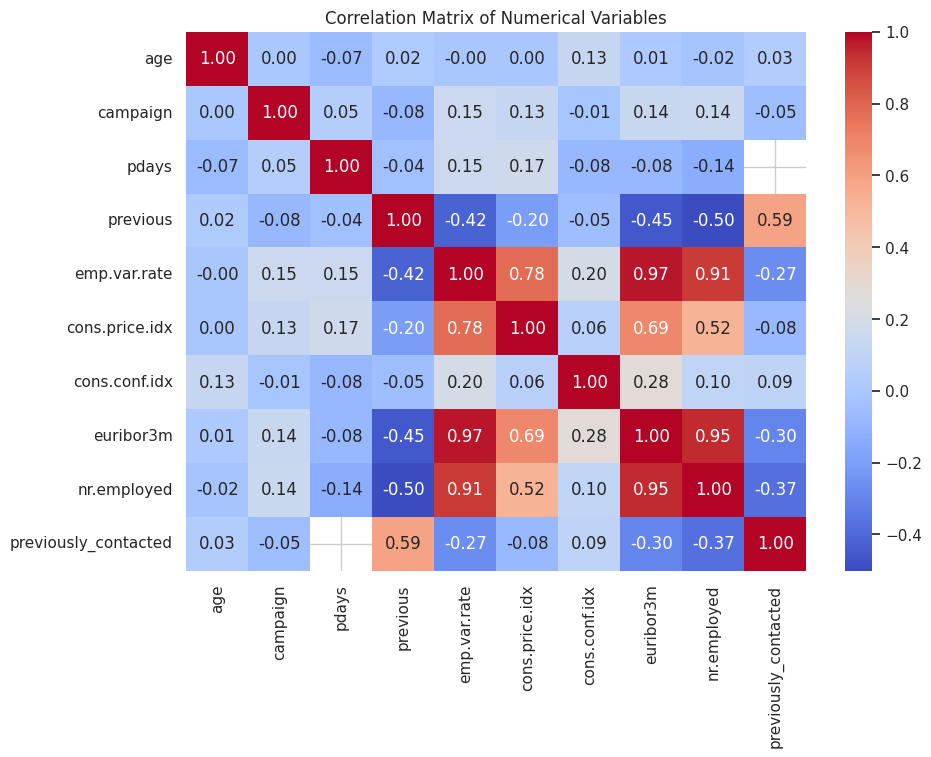

In [45]:
numeric_corr = df.select_dtypes(
    include=['int64', 'float64']
).corr()

plt.figure(figsize=(10, 7))
sns.heatmap(numeric_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Variables')
plt.show()

There is substantial correlation among some economic indicators, particularly euribor3m, emp.var.rate and nr.employed.

This suggests potential multicollinearity when using models such as Logistic Regression, where highly correlated predictors can affect coefficient stability and interpretation.

*Investigate the highly correlated variables before modelling.*

In [46]:
# Identify highly correlated variable pairs
corr_pairs = numeric_corr.abs().unstack()

corr_pairs = corr_pairs[
    (corr_pairs > 0.85) & (corr_pairs < 1.0)
]

print(corr_pairs.sort_values(ascending=False))

emp.var.rate  euribor3m       0.972244
euribor3m     emp.var.rate    0.972244
nr.employed   euribor3m       0.945146
euribor3m     nr.employed     0.945146
emp.var.rate  nr.employed     0.906949
nr.employed   emp.var.rate    0.906949
dtype: float64


emp.var.rate and euribor3m: 0.972 – Very strong positive correlation.

euribor3m and nr.employed: 0.945 – Very strong positive correlation.

emp.var.rate and nr.employed: 0.907 – Very strong positive correlation.

These three economic indicators move closely together, suggesting potential multicollinearity in the Logistic Regression model.

This may make it difficult to distinguish their individual contributions to subscription prediction.

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41176 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   41176 non-null  int64  
 1   job                   41176 non-null  object 
 2   marital               41176 non-null  object 
 3   education             41176 non-null  object 
 4   default               41176 non-null  object 
 5   housing               41176 non-null  object 
 6   loan                  41176 non-null  object 
 7   contact               41176 non-null  object 
 8   month                 41176 non-null  object 
 9   day_of_week           41176 non-null  object 
 10  campaign              41176 non-null  int64  
 11  pdays                 1515 non-null   float64
 12  previous              41176 non-null  int64  
 13  poutcome              41176 non-null  object 
 14  emp.var.rate          41176 non-null  float64
 15  cons.price.idx        41

In [48]:
X = df.drop(columns=['y'])
y = df['y'].map({'no': 0, 'yes': 1})

print("Predictors shape:", X.shape)
print("Target shape:", y.shape)

Predictors shape: (41176, 20)
Target shape: (41176,)


**Split the dataset**

Training data: 60%.
Validation data: 20%.
Testing data: 20%.

In [49]:
from sklearn.model_selection import train_test_split

# First split: 60% training, 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Second split: divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (24705, 20)
Validation: (8235, 20)
Testing: (8236, 20)


Verify the distribution

In [50]:
for name, target in [
    ('Training', y_train),
    ('Validation', y_val),
    ('Testing', y_test)
]:
    print(f"\n{name} distribution:")
    print(target.value_counts(normalize=True) * 100)


Training distribution:
y
0    88.735074
1    11.264926
Name: proportion, dtype: float64

Validation distribution:
y
0    88.731026
1    11.268974
Name: proportion, dtype: float64

Testing distribution:
y
0    88.732394
1    11.267606
Name: proportion, dtype: float64


The stratify parameter successfully preserved the original class imbalance across all three datasets. This ensures that model training, validation and testing use representative proportions of subscribers and non-subscribers

**Establish the majority-class baseline**

In [51]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, y_pred_baseline))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_baseline))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline))

Baseline Accuracy: 0.8873239436619719

Confusion Matrix:
[[7308    0]
 [ 928    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      7308
           1       0.00      0.00      0.00       928

    accuracy                           0.89      8236
   macro avg       0.44      0.50      0.47      8236
weighted avg       0.79      0.89      0.83      8236



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


The model predicts No (0) for every customer, because non-subscribers form the majority class.

Baseline accuracy: 88.73%

This means the model correctly classifies 88.73% of customers simply by predicting that nobody will subscribe.

The most important finding is that recall for subscribers is zero. The model identifies none of the potential customers who would subscribe.

The majority-class baseline achieved 88.73% accuracy, reflecting the dominance of non-subscribers in the dataset. However, it recorded zero precision, recall and F1-score for the subscription class because it failed to identify any actual subscribers. This demonstrates that accuracy alone is insufficient for evaluating the model. A more effective predictive model must identify potential subscribers while maintaining an acceptable level of unnecessary marketing calls.

**Question 2: Select and rank at most three suitable predictive modelling approaches.**

1. Logistic Regression – baseline predictive model and interpretability.
2. Random Forest – captures nonlinear relationships and interactions.
3. Gradient Boosting (HistGradientBoosting or XGBoost) – potentially strong predictive performance on structured data.
We will compare them using the same training and validation datasets before final testing.

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay

Identify numerical and categorical variables

In [53]:
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical variables:", categorical_cols)
print("Numerical variables:", numerical_cols)

Categorical variables: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numerical variables: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']


One observation: pdays has 39,661 missing values because 999 was replaced with missing values. We will handle this during preprocessing. The previously_contacted indicator preserves that information.

*Build the preprocessing pipeline*

In [54]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both transformers
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


*Build and train the Logistic Regression model*

In [55]:
# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Train using training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


*Evaluate it on the validation dataset*

In [56]:
# Predict subscription probabilities and classes
y_val_pred = logistic_model.predict(X_val)
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

# Evaluate performance
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation Precision:", precision_score(y_val, y_val_pred))
print("Validation Recall:", recall_score(y_val, y_val_pred))
print("Validation F1-score:", f1_score(y_val, y_val_pred))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_prob))
print("Validation PR-AUC:", average_precision_score(y_val, y_val_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

Validation Accuracy: 0.8308439587128111
Validation Precision: 0.36168947055324213
Validation Recall: 0.6551724137931034
Validation F1-score: 0.4660789574549636
Validation ROC-AUC: 0.8098837528255853
Validation PR-AUC: 0.4675040388386684

Confusion Matrix:
[[6234 1073]
 [ 320  608]]


he model identifies 608 of the 928 actual subscribers, unlike the baseline, which identified none. However, it also flags 1,073 non-subscribers, meaning some marketing calls would be unnecessary.

Accuracy is lower than the baseline's 88.73%, but accuracy alone is misleading because the dataset is imbalanced.

*Train Random Forest*

In [57]:
# Create Random Forest pipeline
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


*Evaluate Random Forest using the same validation metrics.*

In [58]:
# Predict on validation data
y_val_pred_rf = rf_model.predict(X_val)
y_val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

# Evaluate performance
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred_rf))
print("Validation Precision:", precision_score(y_val, y_val_pred_rf))
print("Validation Recall:", recall_score(y_val, y_val_pred_rf))
print("Validation F1-score:", f1_score(y_val, y_val_pred_rf))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_prob_rf))
print("Validation PR-AUC:", average_precision_score(y_val, y_val_prob_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

Validation Accuracy: 0.8947176684881603
Validation Precision: 0.5661605206073753
Validation Recall: 0.28125
Validation F1-score: 0.3758099352051836
Validation ROC-AUC: 0.7831150190181356
Validation PR-AUC: 0.42895833447082954

Confusion Matrix:
[[7107  200]
 [ 667  261]]


Random Forest is more conservative when identifying potential subscribers:
- Its precision of 56.62% means its selected customers are more likely to subscribe.
- However, it identifies only 28.13% of actual subscribers.
- Logistic Regression identifies more than twice the proportion of actual subscribers.
For a campaign seeking to reach as many potential subscribers as possible, Logistic Regression currently looks more promising.

However, the final decision should consider the cost of unnecessary calls versus missed subscribers, rather than accuracy alone.

*Train the third model_ HistGradientBoosting .*

In [59]:
# Create HistGradientBoosting pipeline
hgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ))
])

# Train the model
hgb_model.fit(X_train, y_train)

print("HistGradientBoosting model trained successfully!")

HistGradientBoosting model trained successfully!


*Evaluate it using the same validation metrics.*

In [60]:
# Predict on validation data
y_val_pred_hgb = hgb_model.predict(X_val)
y_val_prob_hgb = hgb_model.predict_proba(X_val)[:, 1]

# Evaluate performance
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred_hgb))
print("Validation Precision:", precision_score(y_val, y_val_pred_hgb))
print("Validation Recall:", recall_score(y_val, y_val_pred_hgb))
print("Validation F1-score:", f1_score(y_val, y_val_pred_hgb))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_prob_hgb))
print("Validation PR-AUC:", average_precision_score(y_val, y_val_prob_hgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_hgb))

Validation Accuracy: 0.9040680024286581
Validation Precision: 0.6982758620689655
Validation Recall: 0.26185344827586204
Validation F1-score: 0.38087774294670845
Validation ROC-AUC: 0.818450319839738
Validation PR-AUC: 0.4949321785188081

Confusion Matrix:
[[7202  105]
 [ 685  243]]


HistGradientBoosting:
- Correctly identifies 243 subscribers.
- Misses 685 actual subscribers.
- Incorrectly flags only 105 non-subscribers.
- Has the highest precision (69.83%), meaning its positive predictions are more reliable.
- Has the highest PR-AUC (49.49%), indicating the strongest overall precision-recall performance across thresholds.

# The best model depends on the bank's campaign objective. If the priority is reaching as many potential subscribers as possible, Logistic Regression is currently stronger. If the priority is minimizing unnecessary calls, HistGradientBoosting is attractive.

*create a model comparison chart*

In [61]:
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'HistGradientBoosting'],
    'Accuracy': [0.8308, 0.8947, 0.9041],
    'Precision': [0.3617, 0.5662, 0.6983],
    'Recall': [0.6552, 0.2813, 0.2619],
    'F1-score': [0.4661, 0.3758, 0.3809],
    'ROC-AUC': [0.8099, 0.7831, 0.8185],
    'PR-AUC': [0.4675, 0.4290, 0.4949]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8308,0.3617,0.6552,0.4661,0.8099,0.4675
1,Random Forest,0.8947,0.5662,0.2813,0.3758,0.7831,0.4290
2,HistGradientBoosting,0.9041,0.6983,0.2619,0.3809,0.8185,0.4949


1. HistGradientBoosting – strongest overall ranking candidate: Highest accuracy (90.41%), precision (69.83%), ROC-AUC (81.85%) and PR-AUC (49.49%).
2. Logistic Regression – strongest subscriber detection: Highest recall (65.52%) and F1-score (46.61%).
3. Random Forest – third: Its performance is between the other models on some metrics, but it does not lead on any of the six metrics.
For the assignment, I would provisionally rank HistGradientBoosting first and Logistic Regression second based on overall discrimination and PR-AUC, while explaining that Logistic Regression may be preferable when reaching more subscribers is the priority.

One important distinction: These results use the default classification threshold of 0.5. We should not make the final model recommendation until we examine alternative thresholds.

In [62]:
# Calculate precision and recall at different thresholds
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

threshold_results = pd.DataFrame({
    'Threshold': thresholds,
    'Precision': precision[:-1],
    'Recall': recall[:-1]
})

# Examine selected thresholds
threshold_results[
    threshold_results['Threshold'].between(0.2, 0.7)
].iloc[::50]

,Threshold,Precision,Recall
649,0.200000,0.120812,0.987069
699,0.201968,0.121099,0.982759
749,0.203707,0.121508,0.979526
799,0.205617,0.121787,0.975216
849,0.207746,0.122341,0.973060
...,...,...,...
6949,0.649291,0.448505,0.581897
6999,0.661675,0.454939,0.565733
7049,0.671851,0.465580,0.553879
7099,0.683797,0.476689,0.539871


In [63]:
# Find the closest available threshold to each selected value
selected_thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

for t in selected_thresholds:
    row = threshold_results.iloc[
        (threshold_results['Threshold'] - t).abs().argsort()[:1]
    ]
    print(row.to_string(index=False))
    print("-" * 50)

 Threshold  Precision   Recall
       0.2   0.120812 0.987069
--------------------------------------------------
 Threshold  Precision   Recall
  0.300024   0.171374 0.869612
--------------------------------------------------
 Threshold  Precision   Recall
  0.399989    0.26868 0.747845
--------------------------------------------------
 Threshold  Precision   Recall
  0.500054   0.361689 0.655172
--------------------------------------------------
 Threshold  Precision   Recall
  0.599743   0.419565 0.623922
--------------------------------------------------
 Threshold  Precision   Recall
  0.700178   0.490872 0.521552
--------------------------------------------------


In [64]:
for threshold in [0.40, 0.50]:
    y_pred_threshold = (
        y_val_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred_threshold
    ).ravel()

    print(f"\nThreshold: {threshold}")
    print("Correctly identified subscribers (TP):", tp)
    print("Missed subscribers (FN):", fn)
    print("Unnecessary calls (FP):", fp)
    print("Correctly excluded non-subscribers (TN):", tn)


Threshold: 0.4
Correctly identified subscribers (TP): 694
Missed subscribers (FN): 234
Unnecessary calls (FP): 1888
Correctly excluded non-subscribers (TN): 5419

Threshold: 0.5
Correctly identified subscribers (TP): 608
Missed subscribers (FN): 320
Unnecessary calls (FP): 1073
Correctly excluded non-subscribers (TN): 6234


Final test-set evaluation

In [65]:
# Predict subscription probabilities on test data
y_test_prob = logistic_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_test_pred = (y_test_prob >= 0.40).astype(int)

# Evaluate final model
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test Precision:", precision_score(y_test, y_test_pred))
print("Test Recall:", recall_score(y_test, y_test_pred))
print("Test F1-score:", f1_score(y_test, y_test_pred))
print("Test ROC-AUC:", roc_auc_score(y_test, y_test_prob))
print("Test PR-AUC:", average_precision_score(y_test, y_test_prob))

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Test Accuracy: 0.7361583292860612
Test Precision: 0.2574990261005064
Test Recall: 0.7122844827586207
Test F1-score: 0.37825464949928467
Test ROC-AUC: 0.7906628069380746
Test PR-AUC: 0.43864549814669623

Test Confusion Matrix:
[[5402 1906]
 [ 267  661]]


The study developed and evaluated three classification models for predicting term-deposit subscription among bank customers. The results demonstrated that accuracy alone was insufficient for assessing model suitability because of the substantial class imbalance in the dataset, where approximately 11.27% of customers subscribed to term deposits.

HistGradientBoosting achieved the highest validation accuracy (90.41%), ROC-AUC (81.85%) and PR-AUC (49.49%) at the default classification threshold. However, Logistic Regression achieved the highest recall (65.52%) and F1-score (46.61%), demonstrating stronger identification of potential subscribers. Following threshold analysis, a threshold of 0.40 was provisionally selected to prioritise subscriber identification. On the independent test dataset, the model achieved 71.23% recall, 25.75% precision and 79.07% ROC-AUC.

Therefore, Logistic Regression is recommended as the provisional campaign-selection model where identifying more potential subscribers is the priority. Nevertheless, its relatively low precision indicates that a considerable number of unnecessary marketing calls may occur. The bank should assess the financial implications of these calls before deployment. Further evaluation of alternative thresholds and cost-sensitive decision-making will be used to make final recomendation

compare all three models at selected validation threshold

In [66]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

# Store predictions and probabilities from all three models
models = {
    'Logistic Regression': (logistic_model, y_val_prob),
    'Random Forest': (
        rf_model,
        rf_model.predict_proba(X_val)[:, 1]
    ),
    'HistGradientBoosting': (
        hgb_model,
        hgb_model.predict_proba(X_val)[:, 1]
    )
}

thresholds_to_test = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for model_name, (model, probabilities) in models.items():

    for threshold in thresholds_to_test:

        predictions = (probabilities >= threshold).astype(int)

        results.append({
            'Model': model_name,
            'Threshold': threshold,
            'Precision': precision_score(
                y_val, predictions, zero_division=0
            ),
            'Recall': recall_score(y_val, predictions),
            'F1-score': f1_score(y_val, predictions),
            'PR-AUC': average_precision_score(
                y_val, probabilities
            )
        })

# Create comparison table
comparison_df = pd.DataFrame(results)

# Display all threshold comparisons
print("MODEL PERFORMANCE AT DIFFERENT THRESHOLDS")
display(comparison_df.round(4))

# Identify the best F1-score threshold for each model
best_thresholds = (
    comparison_df.loc[
        comparison_df.groupby('Model')['F1-score'].idxmax()
    ]
    .sort_values('F1-score', ascending=False)
    .reset_index(drop=True)
)

print("\nBEST THRESHOLD FOR EACH MODEL")
display(best_thresholds.round(4))

MODEL PERFORMANCE AT DIFFERENT THRESHOLDS


,Model,Threshold,Precision,Recall,F1-score,PR-AUC
0,Logistic Regression,0.2,0.1208,0.9871,0.2153,0.4675
1,Logistic Regression,0.3,0.1714,0.8696,0.2863,0.4675
2,Logistic Regression,0.4,0.2688,0.7478,0.3954,0.4675
3,Logistic Regression,0.5,0.3617,0.6552,0.4661,0.4675
4,Logistic Regression,0.6,0.4199,0.6239,0.5020,0.4675
5,Logistic Regression,0.7,0.4909,0.5216,0.5057,0.4675
6,Random Forest,0.2,0.3800,0.5787,0.4588,0.4290
7,Random Forest,0.3,0.4576,0.4774,0.4673,0.4290
8,Random Forest,0.4,0.5226,0.3739,0.4359,0.4290
9,Random Forest,0.5,0.5644,0.2834,0.3773,0.4290



BEST THRESHOLD FOR EACH MODEL


,Model,Threshold,Precision,Recall,F1-score,PR-AUC
0,HistGradientBoosting,0.2,0.4738,0.5948,0.5275,0.4949
1,Logistic Regression,0.7,0.4909,0.5216,0.5057,0.4675
2,Random Forest,0.3,0.4576,0.4774,0.4673,0.4290


The comparative evaluation identified HistGradientBoosting as the strongest predictive approach, achieving the highest validation F1-score of 52.75% and PR-AUC of 49.49% at a classification threshold of 0.20. Logistic Regression ranked second with an F1-score of 50.57%, while Random Forest ranked third with 46.73%. These findings demonstrate the importance of threshold optimisation in addressing the class imbalance within the dataset. HistGradientBoosting is therefore recommended as the preferred candidate for the bank's marketing campaign, subject to final evaluation on the independent test dataset and consideration of the financial implications of unnecessary calls and missed subscribers

Before making final recomendation

We previously evaluated Logistic Regression on the test set at threshold 0.40. That result cannot serve as the final test evaluation for our revised recommendation.

We should now evaluate HistGradientBoosting at threshold 0.20 on the untouched test data, and use that as the primary final evaluation.

In [67]:
# Generate subscription probabilities on the test dataset
y_test_prob_hgb = hgb_model.predict_proba(X_test)[:, 1]

# Apply the selected validation threshold
selected_threshold = 0.20
y_test_pred_hgb = (
    y_test_prob_hgb >= selected_threshold
).astype(int)

# Calculate final test metrics
print("FINAL HISTGRADIENTBOOSTING TEST RESULTS")
print("Selected Threshold:", selected_threshold)
print("Accuracy:", accuracy_score(y_test, y_test_pred_hgb))
print("Precision:", precision_score(y_test, y_test_pred_hgb))
print("Recall:", recall_score(y_test, y_test_pred_hgb))
print("F1-score:", f1_score(y_test, y_test_pred_hgb))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob_hgb))
print("PR-AUC:", average_precision_score(y_test, y_test_prob_hgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_hgb))

FINAL HISTGRADIENTBOOSTING TEST RESULTS
Selected Threshold: 0.2
Accuracy: 0.8723895094706168
Precision: 0.44818871103622576
Recall: 0.5732758620689655
F1-score: 0.5030732860520094
ROC-AUC: 0.7948031385066907
PR-AUC: 0.45759650516258993

Confusion Matrix:
[[6653  655]
 [ 396  532]]


### Conclusion and Model Recommendation

This study developed and evaluated three machine learning classification models to predict term-deposit subscription among bank customers. The analysis identified a substantial class imbalance, with approximately 11.27% of customers subscribing to term deposits. Consequently, accuracy alone was insufficient for evaluating model performance, necessitating the use of precision, recall, F1-score, ROC-AUC and PR-AUC.

The comparative validation results identified HistGradientBoosting as the strongest candidate, achieving an F1-score of 52.75% and PR-AUC of 49.49% at a classification threshold of 0.20. Logistic Regression ranked second, while Random Forest ranked third based on their respective best F1-scores among the tested thresholds.

HistGradientBoosting was subsequently evaluated on the independent test dataset using the selected threshold of 0.20. It achieved an accuracy of 87.24%, precision of 44.82%, recall of 57.33%, F1-score of 50.31%, ROC-AUC of 79.48% and PR-AUC of 45.76%. The model correctly identified 532 subscribers while missing 396 actual subscribers and incorrectly selecting 655 non-subscribers.

# Therefore, HistGradientBoosting is recommended as the preferred predictive model for supporting the bank's term-deposit marketing campaign. The selected threshold prioritises a reasonable balance between identifying potential subscribers and limiting unnecessary marketing calls. However, the bank should consider the financial costs of unsuccessful calls, the potential value of successful subscriptions and available campaign capacity before operational deployment. Further threshold optimisation and cost-sensitive evaluation could improve the model's practical usefulness.

**3. Recommended Decision Threshold and Trade-off Between Unnecessary Calls and Missed Subscribers**

A classification threshold determines the minimum predicted probability at which a customer is classified as a potential term-deposit subscriber and selected for a marketing call. Customers with predicted probabilities equal to or above the threshold are selected, while those below it are excluded.

For this study, a threshold of 0.20 (20%) is recommended for the HistGradientBoosting model. This threshold was selected because it achieved the highest F1-score (52.75%) among the six thresholds evaluated (0.20, 0.30, 0.40, 0.50, 0.60 and 0.70) on the validation dataset. It provided a reasonable balance between precision (47.38%) and recall (59.48%).
Trade-off analysis
The threshold creates a trade-off between two types of errors:
- Unnecessary marketing calls (False Positives): These occur when customers are predicted to subscribe but do not actually subscribe. A lower threshold increases the number of customers selected, potentially increasing campaign costs and consuming staff time.
- Missed subscribers (False Negatives): These occur when customers are predicted not to subscribe but would actually have subscribed. A higher threshold excludes more customers, potentially causing the bank to miss valuable deposit opportunities.
The final test evaluation at the selected threshold of 0.20 produced the following results:

*Test outcome	Number of customers*

Correctly identified subscribers (True Positives)	532

Missed subscribers (False Negatives)	396

Unnecessary calls (False Positives)	655

Correctly excluded non-subscribers (True Negatives)	6,653

The results indicate that the model correctly identified 532 of the 928 actual subscribers, representing a recall of 57.33%. However, it also selected 655 customers who did not subscribe, representing a precision of 44.82%.

*Implications for the marketing campaign*

A lower threshold, such as 0.20, is appropriate when the bank prioritises reaching a larger proportion of potential subscribers and is willing to accept additional unsuccessful calls. Conversely, increasing the threshold would generally improve precision by selecting customers with higher predicted subscription probabilities, but would reduce recall and increase the risk of missing potential subscribers.

Therefore, the 0.20 threshold is recommended as a provisional operating threshold because it provides the best F1-score among the tested validation thresholds. Nevertheless, the bank should consider the cost of contacting non-subscribers, the expected financial value of successful term deposits and available marketing resources before implementation. If unnecessary calls are particularly expensive, a higher threshold may be more appropriate.
